# Hybrid CNN: best pair and triple
Fine-tuning of the best pair (DenseNet121 + ConvNeXtTiny) and the best triple (VGG16 + DenseNet121 + ConvNeXtTiny) from the screening, with gated fusion and auxiliary classifiers.

## 1. GPU check

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Settings + Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q imagehash
from pathlib import Path
import os, json, time, gc, hashlib, subprocess
import numpy as np, pandas as pd, psutil, imagehash
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

PROJECT   = Path('/content/drive/MyDrive/thesis')
ZIP_PATH  = PROJECT / 'data/raw/agri_vision.zip'
RICE_ZIP  = PROJECT / 'data/raw/riceleafbd.zip'
COMBOS    = [['DenseNet121', 'ConvNeXtTiny'],                  # best pair of the screening
             ['VGG16', 'DenseNet121', 'ConvNeXtTiny']]        # best triple of the screening
CROPS     = ['Tomato', 'Papaya', 'Bottle_Gourd', 'Rice']
H3_FOLDER = 'hybrid'                                          # earlier H3 (VGG16 + ConvNeXtTiny), already trained
REFERENCE = {'Tomato': 'run05_balanced300_moderateaug', 'Papaya': 'run05_balanced_moderateaug',
             'Bottle_Gourd': 'run05_balanced_moderateaug', 'Rice': 'run05_balanced_moderateaug'}   # single CNNs, same setting
IMG_SIZE, TARGET_PER_CLASS = 224, 300
FOLD, SEED, N_FOLDS = 0, 42, 5
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
print('Agri-Vision zip found:', ZIP_PATH.exists(), '| Rice zip found:', RICE_ZIP.exists())

Mounted at /content/drive
Agri-Vision zip found: True | Rice zip found: True


## 3. Agri-Vision: unzip to local disk

In [3]:
import shutil
UNZIP_DIR = Path('/content/data/agri_vision')
print('Agri-Vision zip found in Drive:', ZIP_PATH.exists(), ZIP_PATH)
assert ZIP_PATH.exists(), 'Zip not found: check the file name and folder in Google Drive'

def find_orig():
    return [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()]

if not find_orig():                      # missing or incomplete unzip -> start again cleanly
    shutil.rmtree(UNZIP_DIR, ignore_errors=True)
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

found = find_orig()
if not found:
    print('Still no "Original" folder. Top folders inside the zip:')
    for p in sorted(UNZIP_DIR.rglob('*')):
        if p.is_dir() and len(p.relative_to(UNZIP_DIR).parts) <= 3:
            print('   ', p.relative_to(UNZIP_DIR))
    raise SystemExit('Original images folder not found')
ORIG_DIR = found[0]
print('Original images folder:', ORIG_DIR)

Agri-Vision zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/agri_vision.zip
Original images folder: /content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset


## 4. Agri-Vision: audit, clean and folds

In [4]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
rows = []
for p in tqdm(sorted(q for q in ORIG_DIR.rglob('*') if q.suffix.lower() in IMG_EXT), desc='Hashing'):
    parts = p.relative_to(ORIG_DIR).parts
    rec = {'rel_path': '/'.join(parts), 'split': parts[0], 'label_raw': parts[-2]}
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rec['phash'] = str(imagehash.phash(im.convert('RGB')))
        rec['md5'] = hashlib.md5(p.read_bytes()).hexdigest()
        rec['corrupt'] = False
    except Exception:
        rec['corrupt'] = True
    rows.append(rec)
df = pd.DataFrame(rows).sort_values('rel_path').reset_index(drop=True)
df['label'] = df.label_raw.replace({'Tomato_Downy Mildew': 'Tomato_Downy_Mildew', 'Zucchini_Downy_Midew': 'Zucchini_Downy_Mildew'})
df['crop'] = df.label.str.extract(r'^(Bottle_Gourd|Papaya|Tomato|Zucchini)', expand=False)
df['keep'], df['reason'] = True, ''

def drop(mask, reason):
    m = mask & df.keep
    df.loc[m, 'keep'], df.loc[m, 'reason'] = False, reason
    print(f'{reason:24s} removed {int(m.sum()):5d}   remaining {int(df.keep.sum()):5d}')

drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
drop(df.crop.eq('Zucchini'), 'excluded_zucchini')

kept = df[df.keep].copy()
kept['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(kept, kept.label, groups=kept.phash)):
    kept.iloc[tst, kept.columns.get_loc('fold')] = k
assert kept.md5.is_unique and kept.groupby('phash').fold.nunique().max() == 1
AV_KEPT, AV_DIR = kept, ORIG_DIR
print(kept.groupby('crop').size().rename('clean images').to_string())

Hashing:   0%|          | 0/5246 [00:00<?, ?it/s]

unreadable               removed     0   remaining  5246
label_conflict_exact     removed   754   remaining  4492
duplicate_copy           removed   463   remaining  4029
label_conflict_near      removed    18   remaining  4011
excluded_zucchini        removed   262   remaining  3749
crop
Bottle_Gourd    1491
Papaya          1463
Tomato           795


## 5. RiceLeafBD: unzip, read labels, audit, clean and folds

In [5]:
import shutil
RICE_ROOT = Path('/content/data/riceleafbd')
print('Rice zip found in Drive:', RICE_ZIP.exists(), RICE_ZIP)
assert RICE_ZIP.exists(), 'Rice zip not found: check the file name and folder in Google Drive'
if not RICE_ROOT.exists() or not any(q.suffix.lower() in IMG_EXT for q in RICE_ROOT.rglob('*')):
    shutil.rmtree(RICE_ROOT, ignore_errors=True)
    RICE_ROOT.mkdir(parents=True)
    !unzip -q "{RICE_ZIP}" -d "{RICE_ROOT}"
    for inner in list(RICE_ROOT.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

print('Folder tree (folders with images):')
for p in sorted(q for q in RICE_ROOT.rglob('*') if q.is_dir()):
    n = sum(1 for f in p.iterdir() if f.suffix.lower() in IMG_EXT)
    if n or len(p.relative_to(RICE_ROOT).parts) <= 2:
        print('   ' * (len(p.relative_to(RICE_ROOT).parts) - 1) + f'{p.name}/  ({n} images)')
print('CSV files:', [str(c.relative_to(RICE_ROOT)) for c in RICE_ROOT.rglob('*.csv')])

RICE_CLASSES = [('tungro', 'Rice_Tungro'), ('brown', 'Rice_Brown_Spot'),
                ('bacterial', 'Rice_Bacterial_Leaf_Blight'), ('blight', 'Rice_Bacterial_Leaf_Blight'),
                ('healthy', 'Rice_Healthy')]
def rice_label(text):
    t = str(text).lower().replace('_', ' ').replace('-', ' ')
    for key, lab in RICE_CLASSES:
        if key in t:
            return lab
    return None

files = sorted(q for q in RICE_ROOT.rglob('*') if q.suffix.lower() in IMG_EXT
               and not any('augment' in part.lower() for part in q.relative_to(RICE_ROOT).parts))
r = pd.DataFrame({'rel_path': ['/'.join(q.relative_to(RICE_ROOT).parts) for q in files]})
r['label'] = [next((l for l in (rice_label(x) for x in reversed(q.relative_to(RICE_ROOT).parts[:-1])) if l), None) for q in files]
print(f'\n{len(r)} images found; labelled from folder names: {r.label.notna().sum()}')

if r.label.isna().mean() > 0.5:                                    # folders do not name the classes -> try the CSV
    for c in RICE_ROOT.rglob('*.csv'):
        t = pd.read_csv(c)
        fcol = next((k for k in t.columns if t[k].astype(str).str.lower().str.contains(r'\.(?:jpe?g|png|bmp|webp|tiff?)$').mean() > 0.8), None)
        lcol = next((k for k in t.columns if k != fcol and t[k].map(rice_label).notna().mean() > 0.8), None)
        if fcol and lcol:
            m = dict(zip(t[fcol].astype(str).map(lambda s: Path(s).name), t[lcol].map(rice_label)))
            r['label'] = [m.get(Path(p).name) for p in r.rel_path]
            print(f'Labels taken from {c.name}: file column "{fcol}", label column "{lcol}"; matched {r.label.notna().sum()}')
            break
if r.label.isna().any():
    print('Images WITHOUT a label (skipped):', int(r.label.isna().sum()), r[r.label.isna()].rel_path.head(5).tolist())
r = r[r.label.notna()].reset_index(drop=True)

ph, m5, bad = [], [], []
for p in tqdm(r.rel_path, desc='Hashing rice'):
    try:
        with Image.open(RICE_ROOT / p) as im:
            im.verify()
        with Image.open(RICE_ROOT / p) as im:
            ph.append(str(imagehash.phash(im.convert('RGB')))); bad.append(False)
        m5.append(hashlib.md5((RICE_ROOT / p).read_bytes()).hexdigest())
    except Exception:
        ph.append(None); m5.append(None); bad.append(True)
r['phash'], r['md5'], r['corrupt'], r['crop'] = ph, m5, bad, 'Rice'
r['keep'], r['reason'] = True, ''

print('\nRice cleaning:')
df = r          # drop() from section 4 works on `df`
drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
k_ = df[df.keep]; near = k_[k_.duplicated('phash', keep=False)]
print(f'near-duplicate images kept (same pHash, same label; grouped into one fold): {len(near)}')

paper = pd.Series({'Rice_Healthy': 252, 'Rice_Bacterial_Leaf_Blight': 417, 'Rice_Brown_Spot': 356, 'Rice_Tungro': 530})
audit = pd.DataFrame({'paper': paper, 'found': r.label.value_counts(), 'after cleaning': r[r.keep].label.value_counts()}).fillna(0).astype(int)
audit.loc['Total'] = audit.sum(); display(audit)
(PROJECT / 'audit').mkdir(exist_ok=True)
r.to_csv(PROJECT / 'audit' / 'riceleafbd_files.csv', index=False); audit.to_csv(PROJECT / 'audit' / 'riceleafbd_audit.csv')

RICE_KEPT = r[r.keep].copy()
RICE_KEPT['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(RICE_KEPT, RICE_KEPT.label, groups=RICE_KEPT.phash)):
    RICE_KEPT.iloc[tst, RICE_KEPT.columns.get_loc('fold')] = k
assert RICE_KEPT.groupby('phash').fold.nunique().max() == 1
RICE_OK = RICE_KEPT.label.nunique() == 4 and len(RICE_KEPT) > 500
if not RICE_OK:
    print('\nRice labels look wrong: rice is skipped in this run.')
    CROPS = [c for c in CROPS if c != 'Rice']

Rice zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/riceleafbd.zip
Folder tree (folders with images):
RiceLeafBD A Real-Field Image Dataset for Rice Lea/  (0 images)
   Original Images/  (0 images)
      Bacterial Leaf Blight/  (422 images)
      Brown Spot/  (356 images)
      Healthy Leaf/  (252 images)
      Tungro Virus/  (530 images)
CSV files: []

1560 images found; labelled from folder names: 1560


Hashing rice:   0%|          | 0/1560 [00:00<?, ?it/s]


Rice cleaning:
unreadable               removed     0   remaining  1560
label_conflict_exact     removed    44   remaining  1516
duplicate_copy           removed    87   remaining  1429
label_conflict_near      removed     0   remaining  1429
near-duplicate images kept (same pHash, same label; grouped into one fold): 10


,paper,found,after cleaning
Rice_Bacterial_Leaf_Blight,417,422,335
Rice_Brown_Spot,356,356,347
Rice_Healthy,252,252,252
Rice_Tungro,530,530,495
Total,1555,1560,1429


## 6. The multi-branch hybrid training script

In [6]:
%%writefile /content/train_hybrid_n.py
# Trains ONE multi-branch hybrid (H3 design: gate + helper classifiers) for one crop, then appends its results.
# Usage: python train_hybrid_n.py OUT_FOLDER     (the branches are listed in OUT_FOLDER/config.json, e.g. DenseNet121, ConvNeXtTiny)
#   every branch = one pretrained CNN looking at the same photo
#   gate   = for every feature, a softmax over the branches: how much to trust each branch for THIS photo
#   helper = a small classifier on every branch during training (loss weight 0.3), so every branch must learn
import os, sys, json, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, matthews_corrcoef, confusion_matrix)

OUT = Path(sys.argv[1]); cfg = json.loads((OUT / 'config.json').read_text())
ORIG_DIR, IMG, SEED, FOLD = Path(cfg['orig_dir']), cfg['img_size'], cfg['seed'], cfg['fold']
BATCH = int(os.environ.get('BATCH', cfg['batch']))          # the notebook retries with 16 if the GPU runs out of memory
WEIGHTS = None if os.environ.get('HYBRID_TEST') else 'imagenet'
BRANCHES = cfg['branches']
AUX_W = 0.3                                                  # weight of each helper classifier's loss
name = 'H3_' + '+'.join(BRANCHES)

d = pd.read_csv(OUT / f"{cfg['crop'].lower()}_split.csv")
CLASSES = sorted(d.label.unique()); N = len(CLASSES)
y = d.label.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
te = (d.fold == FOLD).to_numpy(); va = (d.fold == (FOLD + 1) % cfg['n_folds']).to_numpy(); tr = ~(te | va)
keras.mixed_precision.set_global_policy('float32' if os.environ.get('HYBRID_TEST') else 'mixed_float16')
keras.utils.set_random_seed(SEED + FOLD)

X = np.stack([np.asarray(ImageOps.pad(Image.open(ORIG_DIR / p).convert('RGB'), (IMG, IMG), color=(0, 0, 0)),
                         dtype=np.uint8) for p in d.rel_path])
# Moderate augmentation, training images only (identical to Run 05)
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', dtype='float32'), layers.RandomRotation(0.2, dtype='float32'),
    layers.RandomZoom(0.2, dtype='float32'), layers.RandomTranslation(0.1, 0.1, dtype='float32'),
    layers.RandomContrast(0.2, dtype='float32'), layers.RandomBrightness(0.15, value_range=(0, 255), dtype='float32')])

def make_ds(idx, train):
    ds = tf.data.Dataset.from_tensor_slices((X[idx], y[idx]))
    if train:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), tf.one_hot(b, N)), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    # the same label goes to the main output and to the two helper outputs
    return ds.map(lambda a, b: (a, {'main': b, **{f'aux_{k}': b for k in range(len(BRANCHES))}})).prefetch(tf.data.AUTOTUNE)

# ---------------- the hybrid model ----------------
A = keras.applications
RGB_MEAN, RGB_STD = np.array([0.485, 0.456, 0.406], 'float32'), np.array([0.229, 0.224, 0.225], 'float32')
CAFFE_MEAN = np.array([103.939, 116.779, 123.68], 'float32')
CNN = {   # constructor + its own preprocessing (input: raw pixels 0-255, RGB)
    'VGG16':        (A.VGG16,        lambda t: t[..., ::-1] - CAFFE_MEAN),              # BGR minus mean
    'ResNet50':     (A.ResNet50,     lambda t: t[..., ::-1] - CAFFE_MEAN),
    'DenseNet121':  (A.DenseNet121,  lambda t: (t / 255.0 - RGB_MEAN) / RGB_STD),       # 0-1, ImageNet mean/std
    'InceptionV3':  (A.InceptionV3,  lambda t: t / 127.5 - 1.0),                        # -1..1
    'ConvNeXtTiny': (A.ConvNeXtTiny, lambda t: t),                                      # normalises itself
    'EfficientNetV2B0': (A.EfficientNetV2B0, lambda t: t)}                              # normalises itself
inp = keras.Input((IMG, IMG, 3), name='photo')                               # raw pixels 0-255
cnns, proj = [], []
for k, b in enumerate(BRANCHES):
    ctor, prep = CNN[b]
    cnn = ctor(include_top=False, weights=WEIGHTS, input_shape=(IMG, IMG, 3)); cnn.trainable = False
    f = layers.GlobalAveragePooling2D(name=f'features_{b}')(cnn(layers.Lambda(prep, name=f'prep_{b}')(inp), training=False))
    proj.append(layers.Dense(256, activation='relu', name=f'proj_{b}')(layers.Dropout(0.3)(f)))
    cnns.append(cnn)
nb = len(BRANCHES)
both = layers.Concatenate(name='all_branches')(proj)
gate = layers.Softmax(axis=1, name='gate')(layers.Reshape((nb, 256))(layers.Dense(nb * 256, name='gate_logits')(both)))
stacked = layers.Reshape((nb, 256))(both)                                    # (branch, feature)
fused = layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1), name='gated_fusion')([gate, stacked])
main = layers.Dense(N, activation='softmax', dtype='float32', name='main')(layers.Dropout(0.3)(fused))
aux = {f'aux_{k}': layers.Dense(N, activation='softmax', dtype='float32', name=f'aux_{k}')(proj[k]) for k in range(nb)}
model = keras.Model(inp, {'main': main, **aux}, name=name.replace('+', '_'))

# ---------------- training (same two-phase protocol as every single CNN) ----------------
rng = np.random.default_rng(SEED)
parts = []
for c in range(N):                                                           # balanced: every class topped up (Run 05)
    own = np.where(tr & (y == c))[0]
    parts += [own, rng.choice(own, max(cfg['target_per_class'] - len(own), 0), replace=True)]
tr_idx = np.concatenate(parts)
ds_tr, ds_va, ds_te = make_ds(tr_idx, True), make_ds(np.where(va)[0], False), make_ds(np.where(te)[0], False)
LOSS = keras.losses.CategoricalCrossentropy()
opt = lambda lr: keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0)
def compile_(lr):
    model.compile(opt(lr), loss={'main': LOSS, **{k: LOSS for k in aux}},
                  loss_weights={'main': 1.0, **{k: AUX_W for k in aux}},
                  metrics={'main': ['accuracy']})
ACC = 'main_accuracy'

t0 = time.perf_counter()
compile_(cfg['head_lr'])                                                     # phase 1: both CNNs frozen, train the new layers
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['head_epochs'], verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True)])
for cnn in cnns:                                                             # phase 2: fine-tune everything
    cnn.trainable = True
steps = int(np.ceil(len(tr_idx) / BATCH))
compile_(keras.optimizers.schedules.CosineDecay(0.0, (cfg['ft_epochs'] - cfg['warmup_epochs']) * steps,
                                                warmup_target=cfg['ft_lr'], warmup_steps=cfg['warmup_epochs'] * steps))
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['ft_epochs'], verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_' + ACC, mode='max', patience=cfg['ft_patience'],
                                                        restore_best_weights=True), keras.callbacks.TerminateOnNaN()])
minutes = (time.perf_counter() - t0) / 60

# ---------------- evaluation ----------------
o_te, o_va = model.predict(ds_te, verbose=0), model.predict(ds_va, verbose=0)
p_te, p_va = o_te['main'], o_va['main']
pred, true, vpred, vtrue = p_te.argmax(1), y[te], p_va.argmax(1), y[va]
(OUT / 'preds').mkdir(exist_ok=True); (OUT / 'history').mkdir(exist_ok=True)
np.save(OUT / 'preds' / f'{name}_test_proba.npy', p_te); np.save(OUT / 'preds' / f'{name}_val_proba.npy', p_va)
pd.DataFrame({'rel_path': d.rel_path[te].values, 'y_true': true, 'y_pred': pred}).to_csv(OUT / 'preds' / f'{name}.csv', index=False)
pd.concat([pd.DataFrame(h1.history).assign(phase='head'), pd.DataFrame(h2.history).assign(phase='finetune')]
          ).to_csv(OUT / 'history' / f'{name}.csv', index=False)

LAB = range(N)
per = lambda fn, t, p: json.dumps(dict(zip(CLASSES, np.round(fn(t, p, average=None, labels=LAB, zero_division=0), 3).tolist())))
extra = {}
for k, b in enumerate(BRANCHES):   # each branch ON ITS OWN inside the hybrid (its helper classifier), validation
    extra[f'val_macro_f1_branch_{b}'] = f1_score(vtrue, o_va[f'aux_{k}'].argmax(1), average='macro', zero_division=0)
# average gate weight of every branch, per TRUE class (validation): which branch does the hybrid trust for which disease?
g = keras.Model(inp, gate).predict(make_ds(np.where(va)[0], False).map(lambda a, b: a), verbose=0).mean(2)   # (photos, branch)
extra['gate_per_class'] = json.dumps({c: {b: round(float(g[vtrue == i, k].mean()), 3) for k, b in enumerate(BRANCHES)}
                                      for i, c in enumerate(CLASSES)})
best = int(np.nanargmax(h2.history['val_' + ACC]))
row = {'run': cfg['run'], 'crop': cfg['crop'], 'model': name, 'branches': '+'.join(BRANCHES), 'fold': FOLD, 'batch': BATCH,
       'n_train': int(tr.sum()), 'n_train_effective': int(len(tr_idx)), 'n_val': int(va.sum()), 'n_test': int(te.sum()),
       'img_size': IMG, 'aux_weight': AUX_W,
       'val_accuracy': accuracy_score(vtrue, vpred), 'val_macro_f1': f1_score(vtrue, vpred, average='macro', zero_division=0),
       'accuracy': accuracy_score(true, pred), 'balanced_accuracy': balanced_accuracy_score(true, pred),
       'macro_precision': precision_score(true, pred, average='macro', zero_division=0),
       'macro_recall': recall_score(true, pred, average='macro', zero_division=0),
       'macro_f1': f1_score(true, pred, average='macro', zero_division=0),
       'weighted_f1': f1_score(true, pred, average='weighted', zero_division=0),
       'cohen_kappa': cohen_kappa_score(true, pred), 'mcc': matthews_corrcoef(true, pred),
       'best_val_acc': float(h2.history['val_' + ACC][best]), 'train_acc_at_best': float(h2.history[ACC][best]),
       'epochs_head': len(h1.history['loss']), 'epochs_finetune': len(h2.history['loss']),
       'params_M': model.count_params() / 1e6, 'train_minutes': minutes,
       'per_class_precision': per(precision_score, true, pred), 'per_class_recall': per(recall_score, true, pred),
       'per_class_f1': per(f1_score, true, pred), 'val_per_class_f1': per(f1_score, vtrue, vpred),
       'confusion_matrix': json.dumps(confusion_matrix(true, pred, labels=LAB).tolist()), **extra}
res = OUT / 'results.csv'
new = pd.DataFrame([row])
if res.exists():
    new = pd.concat([pd.read_csv(res), new], ignore_index=True)
new.to_csv(res, index=False)
print(f"{name:40s} VAL macroF1 {row['val_macro_f1']:.3f} | test acc {row['accuracy']:.3f} macroF1 {row['macro_f1']:.3f} | "
      f"train_acc {row['train_acc_at_best']:.3f} | {row['params_M']:.1f}M params | batch {BATCH} ({minutes:.1f} min)")

Writing /content/train_hybrid_n.py


## 7. Train: every combination on every crop

In [7]:
def crop_data(crop):
    if crop == 'Rice':
        return RICE_KEPT, RICE_ROOT
    return AV_KEPT[AV_KEPT.crop == crop], AV_DIR
folder = lambda combo: 'hybrid_' + '_'.join(combo)
mname = lambda combo: 'H3_' + '+'.join(combo)

for combo in COMBOS:
    for crop in CROPS:
        d, root = crop_data(crop)
        d = d.sort_values('rel_path').reset_index(drop=True)
        OUT = PROJECT / 'experiments' / crop.lower() / folder(combo)
        OUT.mkdir(parents=True, exist_ok=True)
        res = OUT / 'results.csv'
        if res.exists() and mname(combo) in set(pd.read_csv(res).model):
            print(f'[{mname(combo)} | {crop}] already done'); continue
        d.to_csv(OUT / f'{crop.lower()}_split.csv', index=False)
        te, va = (d.fold == FOLD).to_numpy(), (d.fold == (FOLD + 1) % N_FOLDS).to_numpy()
        target = max(TARGET_PER_CLASS, int(d[~(te | va)].label.value_counts().max()))
        cfg = {'run': folder(combo), 'crop': crop, 'branches': combo, 'fold': FOLD, 'seed': SEED, 'n_folds': N_FOLDS,
               'img_size': IMG_SIZE, 'batch': 32, 'target_per_class': target, 'class_weights': False, 'augment': 'moderate',
               'head_epochs': 15, 'head_lr': 1e-3, 'ft_epochs': 40, 'ft_lr': 3e-5, 'warmup_epochs': 2, 'ft_patience': 10,
               'optimizer': 'AdamW(weight_decay=1e-4, clipnorm=1.0)',
               'early_stopping': 'head: val_loss p3; fine-tune: val_main_accuracy p10; restore best',
               'orig_dir': str(root), 'out': str(OUT)}
        (OUT / 'config.json').write_text(json.dumps(cfg, indent=2))
        for batch in ['32', '16']:
            p = subprocess.run(['python', '/content/train_hybrid_n.py', str(OUT)], capture_output=True, text=True,
                               env={**os.environ, 'BATCH': batch})
            if p.returncode == 0 or not any(k in p.stderr for k in ('RESOURCE_EXHAUSTED', 'OOM', 'out of memory')):
                break
            print(f'[{mname(combo)} | {crop}] out of GPU memory with batch {batch}, retrying with 16')
        last = [l for l in p.stdout.strip().splitlines() if l.strip()]
        print(f'[{crop:12s}] {last[-1]}' if p.returncode == 0 and last else f'[{mname(combo)} | {crop}] FAILED:\n' + p.stderr[-2000:])
print('\nAll done.')

[H3_DenseNet121+ConvNeXtTiny | Tomato] already done
[H3_DenseNet121+ConvNeXtTiny | Papaya] already done
[H3_DenseNet121+ConvNeXtTiny | Bottle_Gourd] already done
[H3_DenseNet121+ConvNeXtTiny | Rice] already done
[H3_VGG16+DenseNet121+ConvNeXtTiny | Tomato] already done
[H3_VGG16+DenseNet121+ConvNeXtTiny | Papaya] already done
[H3_VGG16+DenseNet121+ConvNeXtTiny | Bottle_Gourd] already done
[H3_VGG16+DenseNet121+ConvNeXtTiny | Rice] already done

All done.


## 8. Results: hybrids vs single CNNs (validation macro-F1 decides; test fold 0 reported only)

In [8]:
def results(crop, run):
    f = PROJECT / 'experiments' / crop.lower() / run / 'results.csv'
    return pd.read_csv(f).drop_duplicates('model', keep='last').set_index('model') if f.exists() else None
SINGLES = ['VGG16', 'DenseNet121', 'ConvNeXtTiny']
SOURCES = [(lambda c: REFERENCE[c], {m: m for m in SINGLES}),
           (lambda c: H3_FOLDER, {'H3_gated_aux': 'H3 VGG16+ConvNeXtTiny'})] + \
          [(lambda c, cb=cb: folder(cb), {mname(cb): mname(cb).replace('H3_', 'H3 ')}) for cb in COMBOS]
COLS = SINGLES + ['H3 VGG16+ConvNeXtTiny'] + [mname(cb).replace('H3_', 'H3 ') for cb in COMBOS]
tabs, params = {}, {}
for col, title in [('val_macro_f1', 'VALIDATION macro-F1'), ('macro_f1', 'TEST fold 0 macro-F1'), ('accuracy', 'TEST fold 0 accuracy')]:
    t = pd.DataFrame(index=CROPS, columns=COLS, dtype=float)
    for crop in CROPS:
        for run_of, names in SOURCES:
            r = results(crop, run_of(crop))
            for m, label in names.items():
                if r is not None and m in r.index:
                    t.loc[crop, label] = round(100 * r.loc[m, col], 1); params[label] = round(r.loc[m, 'params_M'], 1)
    t.loc['MEAN (4 crops)'] = t.mean().round(1)
    tabs[title] = t
    print(f'\n{title} (%):'); display(t)
v = tabs['VALIDATION macro-F1'].drop('MEAN (4 crops)')
best_single = v[SINGLES].max(axis=1)
print('\nEach hybrid vs the BEST single CNN of each crop (validation):')
display(pd.DataFrame({h: {'mean change (points)': round((v[h] - best_single).mean(), 1),
                          'crops better': f"{int((v[h] > best_single).sum())} of {int(v[h].notna().sum())}",
                          'params (M)': params.get(h)} for h in COLS[3:]}).T)


VALIDATION macro-F1 (%):


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Tomato,73.8,73.6,72.8,67.7,76.8,73.7
Papaya,74.2,67.9,67.6,74.0,72.2,72.5
Bottle_Gourd,70.4,66.9,70.6,73.7,72.0,73.2
Rice,95.7,94.8,96.4,96.8,95.8,96.7
MEAN (4 crops),78.5,75.8,76.8,78.0,79.2,79.0



TEST fold 0 macro-F1 (%):


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Tomato,75.2,71.3,69.1,67.2,71.5,70.9
Papaya,70.7,66.8,68.3,73.5,70.1,73.2
Bottle_Gourd,73.7,70.7,76.1,78.5,79.1,78.8
Rice,93.3,92.4,97.7,96.7,95.8,96.1
MEAN (4 crops),78.2,75.3,77.8,79.0,79.1,79.8



TEST fold 0 accuracy (%):


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Tomato,77.7,74.3,73.0,73.6,76.4,74.3
Papaya,73.7,69.4,69.4,74.7,72.4,75.1
Bottle_Gourd,78.8,77.2,80.8,82.1,82.8,82.8
Rice,93.3,91.9,97.5,96.5,95.4,95.8
MEAN (4 crops),80.9,78.2,80.2,81.7,81.8,82.0



Each hybrid vs the BEST single CNN of each crop (validation):


,mean change (points),crops better,params (M)
H3 VGG16+ConvNeXtTiny,-0.7,2 of 4,43.0
H3 DenseNet121+ConvNeXtTiny,0.4,2 of 4,35.6
H3 VGG16+DenseNet121+ConvNeXtTiny,0.3,2 of 4,50.8


## 9. Which diseases improved? (test fold 0, per-class F1)

In [9]:
for crop in CROPS:
    rows = {}
    for run_of, names in SOURCES:
        r = results(crop, run_of(crop))
        for m, label in names.items():
            if r is not None and m in r.index:
                rows[label] = json.loads(r.loc[m, 'per_class_f1'])
    if rows:
        t = (100 * pd.DataFrame(rows)).round(1); t.index = [i.replace(crop + '_', '') for i in t.index]
        print(f'\n{crop}: test per-class F1 (%)'); display(t)


Tomato: test per-class F1 (%)


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Downy_Mildew,77.8,70.6,60.9,55.6,60.9,70.6
Healthy,89.7,83.7,90.4,88.7,91.1,87.9
Mosaic,62.5,61.1,54.5,62.9,61.8,60.0
Spot,75.9,77.8,69.9,75.3,77.1,72.5
White_Spot,70.0,63.2,70.0,53.8,66.7,63.6



Papaya: test per-class F1 (%)


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Bacterial_Blight,67.7,60.7,58.2,75.4,72.1,75.4
Carica_Insect_Hole,67.1,60.7,58.8,67.2,66.7,70.4
Curled_Yellow_Spot,84.7,83.1,84.1,84.7,84.4,84.7
Healthy,83.5,72.4,80.9,82.9,76.3,77.5
Mosaic_Virus,52.6,58.3,53.7,56.6,58.2,60.9
Pathogen_Symptoms,72.6,66.0,67.3,72.7,66.7,73.1
Yellow_Necrotic_Spots_Holes,66.7,66.7,75.0,75.0,66.7,70.6



Bottle_Gourd: test per-class F1 (%)


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Alternaria_Leaf_Blight,76.2,75.7,76.3,77.7,78.0,78.8
Anthracnose,82.7,74.6,77.6,81.1,79.5,79.4
Downy_Mildew,84.9,85.4,83.5,88.7,86.2,87.4
Early_Alternaria_Leaf_Blight,54.5,54.5,67.5,62.7,67.6,65.8
Fungal_Damage_Leaf,47.1,33.3,50.0,62.5,61.5,58.8
Healthy,89.3,86.0,89.9,90.6,92.9,92.9
Mosaic_Virus,81.3,85.2,87.6,86.0,87.8,88.7



Rice: test per-class F1 (%)


,VGG16,DenseNet121,ConvNeXtTiny,H3 VGG16+ConvNeXtTiny,H3 DenseNet121+ConvNeXtTiny,H3 VGG16+DenseNet121+ConvNeXtTiny
Bacterial_Leaf_Blight,87.9,85.0,95.2,94.3,92.2,93.4
Brown_Spot,95.1,95.8,99.3,97.9,97.9,96.4
Healthy,97.4,100.0,100.0,100.0,100.0,100.0
Tungro,92.9,88.6,96.3,94.8,93.0,94.4


## 10. Inside the hybrids: gate weights per disease and each branch on its own

In [10]:
for cb in COMBOS:
    for crop in CROPS:
        r = results(crop, folder(cb))
        if r is None or mname(cb) not in r.index:
            continue
        row = r.loc[mname(cb)]
        g = pd.DataFrame(json.loads(row['gate_per_class'])).T.round(2); g.index = [i.replace(crop + '_', '') for i in g.index]
        print(f'\n{mname(cb)} | {crop}: gate weight per branch (validation)'); display(g)
        alone = ' | '.join(f"{b} alone {100*row[f'val_macro_f1_branch_{b}']:.1f}" for b in cb)
        print(f'validation macro-F1: {alone} | fused {100*row.val_macro_f1:.1f}')


H3_DenseNet121+ConvNeXtTiny | Tomato: gate weight per branch (validation)


,DenseNet121,ConvNeXtTiny
Downy_Mildew,0.41,0.59
Healthy,0.42,0.58
Mosaic,0.44,0.56
Spot,0.45,0.56
White_Spot,0.45,0.55


validation macro-F1: DenseNet121 alone 63.9 | ConvNeXtTiny alone 66.6 | fused 76.8

H3_DenseNet121+ConvNeXtTiny | Papaya: gate weight per branch (validation)


,DenseNet121,ConvNeXtTiny
Bacterial_Blight,0.40,0.60
Carica_Insect_Hole,0.39,0.61
Curled_Yellow_Spot,0.39,0.61
Healthy,0.38,0.62
Mosaic_Virus,0.39,0.61
Pathogen_Symptoms,0.38,0.62
Yellow_Necrotic_Spots_Holes,0.41,0.59


validation macro-F1: DenseNet121 alone 64.0 | ConvNeXtTiny alone 65.7 | fused 72.2

H3_DenseNet121+ConvNeXtTiny | Bottle_Gourd: gate weight per branch (validation)


,DenseNet121,ConvNeXtTiny
Alternaria_Leaf_Blight,0.40,0.60
Anthracnose,0.40,0.60
Downy_Mildew,0.42,0.58
Early_Alternaria_Leaf_Blight,0.43,0.57
Fungal_Damage_Leaf,0.42,0.57
Healthy,0.43,0.57
Mosaic_Virus,0.41,0.59


... (7 outputs left out)

,VGG16,DenseNet121,ConvNeXtTiny
Alternaria_Leaf_Blight,0.18,0.36,0.46
Anthracnose,0.19,0.35,0.46
Downy_Mildew,0.20,0.35,0.45
Early_Alternaria_Leaf_Blight,0.18,0.35,0.47
Fungal_Damage_Leaf,0.18,0.35,0.46
Healthy,0.19,0.35,0.46
Mosaic_Virus,0.19,0.36,0.45


validation macro-F1: VGG16 alone 68.6 | DenseNet121 alone 68.5 | ConvNeXtTiny alone 70.0 | fused 73.2

H3_VGG16+DenseNet121+ConvNeXtTiny | Rice: gate weight per branch (validation)


,VGG16,DenseNet121,ConvNeXtTiny
Bacterial_Leaf_Blight,0.19,0.28,0.52
Brown_Spot,0.21,0.28,0.51
Healthy,0.20,0.26,0.54
Tungro,0.19,0.30,0.51


validation macro-F1: VGG16 alone 95.5 | DenseNet121 alone 94.2 | ConvNeXtTiny alone 93.6 | fused 96.7


## 11. Training curves (training vs validation accuracy) and save everything

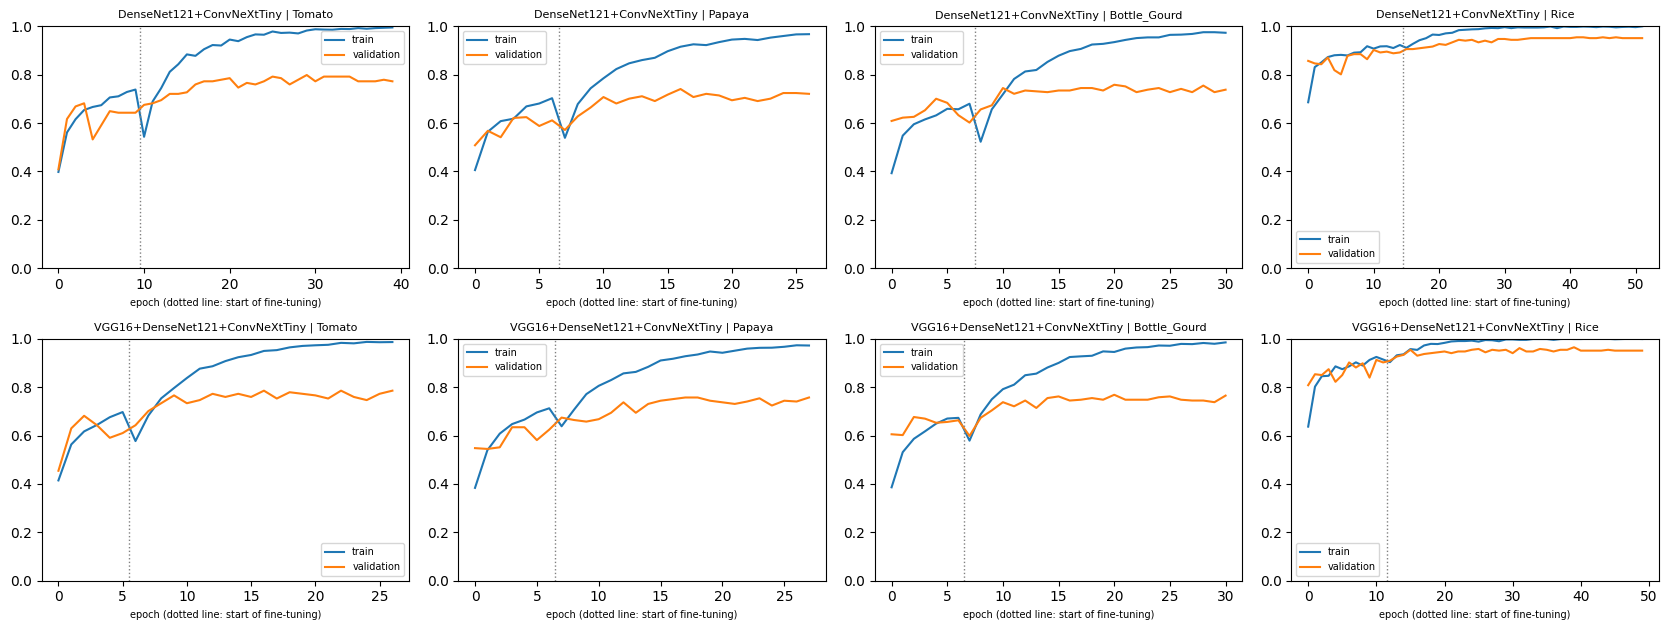

Saved /content/drive/MyDrive/thesis/experiments/hybrid_stage2_results.xlsx and figures/hybrid_stage2_training_curves.png


In [11]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(COMBOS), len(CROPS), figsize=(4.2 * len(CROPS), 3.2 * len(COMBOS)), squeeze=False)
for i, cb in enumerate(COMBOS):
    for j, crop in enumerate(CROPS):
        ax, f = axes[i, j], PROJECT / 'experiments' / crop.lower() / folder(cb) / 'history' / f'{mname(cb)}.csv'
        if f.exists():
            h = pd.read_csv(f).reset_index(drop=True)
            ax.plot(h['main_accuracy'], label='train'); ax.plot(h['val_main_accuracy'], label='validation')
            ax.axvline((h.phase == 'head').sum() - 0.5, color='grey', ls=':', lw=1); ax.set_ylim(0, 1); ax.legend(fontsize=7)
        ax.set_title(f"{'+'.join(cb)} | {crop}", fontsize=8); ax.set_xlabel('epoch (dotted line: start of fine-tuning)', fontsize=7)
plt.tight_layout(); (PROJECT / 'figures').mkdir(exist_ok=True)
fig.savefig(PROJECT / 'figures' / 'hybrid_stage2_training_curves.png', dpi=150); plt.show()
with pd.ExcelWriter(PROJECT / 'experiments' / 'hybrid_stage2_results.xlsx') as xw:
    for title, t in tabs.items():
        t.to_excel(xw, sheet_name=title[:31])
print('Saved', PROJECT / 'experiments' / 'hybrid_stage2_results.xlsx', 'and figures/hybrid_stage2_training_curves.png')